# Лабораторная работа №2. Логистическая и линейная регрессия

Датасеты, разбиение и метрики — те же, что в лабораторной №1 (их выбор обоснован там):
- **Bank Marketing** — классификация «откроет ли клиент депозит», метрики ROC-AUC (основная), PR-AUC, F1;
- **Metro Interstate Traffic Volume** — регрессия почасового трафика, метрики MAE, RMSE, R², разбиение по времени.

In [1]:
# Подключаем пакет mllabs и библиотеки
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline

from mllabs import data as D
from mllabs.evaluation import (ResultStore, Timer, classification_metrics, compare_cv,
                               oof_threshold, regression_metrics)
from mllabs.models.linear import LinearRegressionScratch, LogisticRegressionScratch
from mllabs.pipelines import bank_preprocessor, metro_preprocessor

pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid")
store = ResultStore("lab2_linear", "Линейные модели")

In [2]:
# Разбиения те же, что в остальных лабораторных
Xb_train, Xb_test, yb_train, yb_test = D.bank_split()
Xm_train, Xm_test, ym_train, ym_test = D.metro_split()
bank_cv, metro_cv = D.bank_cv(), D.metro_cv()
print(Xb_train.shape, Xb_test.shape, Xm_train.shape, Xm_test.shape)

(36168, 15) (9043, 15) (32460, 8) (8115, 8)


## 2. Бейзлайн

Признаки бейзлайна общие для всех лабораторных (числа как есть + one-hot категорий). Модели — `LogisticRegression` и `LinearRegression` с параметрами по умолчанию; у логистической регрессии только увеличено `max_iter`, иначе на немасштабированных признаках `lbfgs` не успевает сойтись.

In [3]:
# Бейзлайн логистической регрессии
logreg_base = make_pipeline(bank_preprocessor(), LogisticRegression(max_iter=1000))
with Timer() as t:
    logreg_base.fit(Xb_train, yb_train)
store.add("classification", "baseline", "LogisticRegression()",
          classification_metrics(yb_test, logreg_base.predict_proba(Xb_test)[:, 1]), t.seconds)

# Бейзлайн линейной регрессии
linreg_base = make_pipeline(metro_preprocessor(rich=False), LinearRegression())
with Timer() as t:
    linreg_base.fit(Xm_train, ym_train)
store.add("regression", "baseline", "LinearRegression()",
          regression_metrics(ym_test, linreg_base.predict(Xm_test)), t.seconds)

display(store.table("classification"))
display(store.table("regression"))

,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,LogisticRegression(),0.7709,0.4096,0.2799,0.6727,0.1767,0.5,5.0456


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,LinearRegression(),1575.7271,1797.3501,0.1677,0.0552


**Выводы по бейзлайну.**
- Классификация: ROC-AUC = 0.771 — уже намного лучше KNN-бейзлайна, потому что линейная модель сама подбирает веса признаков. Но при пороге 0.5 recall всего 18%: модель редко решается сказать «да» из-за дисбаланса классов.
- Регрессия: R² = 0.17, MAE ≈ 1576. Линейная модель не может описать два пика в будни, имея только число `hour`: она умеет лишь «трафик растёт или падает с часом».

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

**Классификация:**
1. **Масштабирование**: регуляризация штрафует все коэффициенты одинаково, поэтому признаки должны быть в одном масштабе; заодно ускоряется сходимость.
2. **Новые признаки**: логарифмы скошенных величин и флаг «раньше звонили». Линейная модель не умеет сама «сжимать» хвосты распределений.
3. **Веса классов** (`class_weight="balanced"`): модель сильнее штрафуется за пропуск редкого класса — это должно поднять recall и F1, но почти не изменит ROC-AUC.
4. **Подбор силы регуляризации C** на CV.

**Регрессия:**
1. Зависимость трафика от часа сильно нелинейна (два пика в будни), а число `hour` линейная модель может только умножить на один коэффициент. Гипотеза: **one-hot для часа, дня недели и месяца**.
2. Профиль дня в будни и выходные разный, поэтому нужен **признак-взаимодействие «час × тип дня»** (будни / суббота / воскресенье / праздник).
3. **Очистка погоды** (0 K и 9831 мм дождя) — выбросы тянут на себя коэффициенты МНК.
4. **L2-регуляризация (Ridge)** с подбором alpha: one-hot признаков после взаимодействий около сотни.

In [4]:
# Проверка гипотез для классификации
clf_scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "F1": "f1"}
clf_hyp = compare_cv({
    "0. Бейзлайн": make_pipeline(bank_preprocessor(), LogisticRegression(max_iter=1000)),
    "1. + масштабирование": make_pipeline(bank_preprocessor(scale=True), LogisticRegression(max_iter=1000)),
    "2. + новые признаки": make_pipeline(bank_preprocessor(rich=True, scale=True), LogisticRegression(max_iter=1000)),
    "3. + class_weight=balanced": make_pipeline(bank_preprocessor(rich=True, scale=True),
                                                LogisticRegression(max_iter=1000, class_weight="balanced")),
}, Xb_train, yb_train, bank_cv, clf_scoring)
clf_hyp

,ROC-AUC,ROC-AUC std,PR-AUC,PR-AUC std,F1,F1 std
Гипотеза,,,,,,
0. Бейзлайн,0.7596,0.0027,0.3974,0.0087,0.2675,0.0124
1. + масштабирование,0.7628,0.0030,0.4021,0.0084,0.2749,0.0129
2. + новые признаки,0.7663,0.0028,0.4052,0.0071,0.2767,0.0145
3. + class_weight=balanced,0.7666,0.0033,0.4020,0.0061,0.3750,0.0049


In [5]:
# Подбор C и весов классов по ROC-AUC
clf_search = GridSearchCV(
    make_pipeline(bank_preprocessor(rich=True, scale=True), LogisticRegression(max_iter=1000)),
    {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10],
     "logisticregression__class_weight": [None, "balanced"]},
    scoring="roc_auc", cv=bank_cv, n_jobs=-1)
clf_search.fit(Xb_train, yb_train)
display(pd.DataFrame(clf_search.cv_results_).pivot(
    index="param_logisticregression__C", columns="param_logisticregression__class_weight",
    values="mean_test_score").rename(columns=lambda c: "без весов" if pd.isna(c) else c))
print("Лучшие параметры:", clf_search.best_params_, "| ROC-AUC CV:", round(clf_search.best_score_, 4))

param_logisticregression__class_weight,без весов,balanced
param_logisticregression__C,,
0.001,0.7375,0.7504
0.010,0.7630,0.7664
0.100,0.7665,0.7669
1.000,0.7663,0.7666
10.000,0.7661,0.7666


Лучшие параметры: {'logisticregression__C': 0.1, 'logisticregression__class_weight': 'balanced'} | ROC-AUC CV: 0.7669


In [6]:
# Проверка гипотез для регрессии
reg_scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
RAW_WEATHER = ["temp", "rain_1h", "snow_1h", "clouds_all"]
reg_hyp = compare_cv({
    "0. Бейзлайн": make_pipeline(metro_preprocessor(rich=False), LinearRegression()),
    "1. one-hot час, день недели, месяц": make_pipeline(
        metro_preprocessor(RAW_WEATHER + ["is_holiday"], ["hour", "dayofweek", "month", "weather_main"]),
        LinearRegression()),
    "2. + час × тип дня": make_pipeline(
        metro_preprocessor(RAW_WEATHER, ["hour_daytype", "month", "weather_main"]), LinearRegression()),
    "3. + очищенная погода": make_pipeline(
        metro_preprocessor(D.METRO_WEATHER, ["hour_daytype", "month", "weather_main"]), LinearRegression()),
}, Xm_train, ym_train, metro_cv, reg_scoring)
reg_hyp

,MAE,MAE std,RMSE,RMSE std,R2,R2 std
Гипотеза,,,,,,
0. Бейзлайн,1598.6500,47.4760,2375.7797,1145.7349,-0.7480,1.8232
"1. one-hot час, день недели, месяц",596.6351,31.0439,1181.8346,799.9374,0.4907,0.7036
2. + час × тип дня,312.7885,40.1981,747.5640,593.1986,0.7726,0.3482
3. + очищенная погода,306.6714,35.6135,464.3200,51.3476,0.9441,0.0125


In [7]:
# Подбор alpha у Ridge на лучшем наборе признаков
REG_NUM, REG_CAT = D.METRO_WEATHER, ["hour_daytype", "month", "weather_main"]
reg_search = GridSearchCV(
    make_pipeline(metro_preprocessor(REG_NUM, REG_CAT, scale=True), Ridge()),
    {"ridge__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_mean_absolute_error", cv=metro_cv, n_jobs=-1)
reg_search.fit(Xm_train, ym_train)
display((-pd.DataFrame(reg_search.cv_results_).set_index("param_ridge__alpha")["mean_test_score"])
        .rename("MAE на CV").to_frame())
print("Лучшие параметры:", reg_search.best_params_)

,MAE на CV
param_ridge__alpha,
0.01,306.6822
0.10,306.7817
1.00,308.2632
10.00,337.8792
100.00,611.5530


Лучшие параметры: {'ridge__alpha': 0.01}


**Результаты проверки гипотез.**

*Классификация:*
- Масштабирование: ROC-AUC 0.760 → 0.763 — небольшой, но стабильный прирост, плюс быстрая сходимость. Подтверждена.
- Новые признаки: 0.763 → 0.766. Логарифмы скошенных величин линейной модели полезны. Подтверждена.
- `class_weight="balanced"`: ROC-AUC не изменился, а F1 при пороге 0.5 вырос с 0.28 до 0.38. Подтверждена: веса классов сдвигают вероятности, но не ранжирование.
- По сетке C лучший результат дала регуляризация **C = 0.1** с балансировкой классов, однако при C ≥ 0.1 различия в четвёртом знаке. Слишком сильная регуляризация (C = 0.001) заметно вредит.

*Регрессия:*
- One-hot часа, дня недели и месяца: MAE 1599 → 597, R² −0.75 → 0.49. Подтверждена.
- Взаимодействие «час × тип дня»: MAE 597 → 313. Самая сильная гипотеза: у будней и выходных разная форма суточной кривой, и линейной модели нужно иметь отдельный коэффициент для каждой пары.
- Очистка погоды: MAE 313 → 307, но RMSE 748 → 464, а R² 0.77 → 0.94. Выбросы (0 K и 9831 мм дождя) давали огромные промахи на отдельных фолдах. Подтверждена.
- Ridge: лучшее alpha оказалось минимальным (0.01), с ростом alpha ошибка только растёт. Признаков около сотни, а объектов 32 тысячи, поэтому переобучения нет и регуляризация не нужна. Гипотеза **не подтвердилась**.

### 3.2. Улучшенный бейзлайн

In [8]:
# Классификация: лучшая модель и порог по out-of-fold прогнозам
logreg_best = clf_search.best_estimator_
thr = oof_threshold(logreg_best, Xb_train, yb_train, bank_cv)
with Timer() as t:
    logreg_best.fit(Xb_train, yb_train)
C, cw = clf_search.best_params_["logisticregression__C"], clf_search.best_params_["logisticregression__class_weight"]
store.add("classification", "improved", f"LogisticRegression(C={C}, class_weight={cw}) + scale + features",
          classification_metrics(yb_test, logreg_best.predict_proba(Xb_test)[:, 1], thr), t.seconds)

# Регрессия: Ridge с лучшим alpha
ridge_best = reg_search.best_estimator_
with Timer() as t:
    ridge_best.fit(Xm_train, ym_train)
alpha = reg_search.best_params_["ridge__alpha"]
store.add("regression", "improved", f"Ridge(alpha={alpha}) + hour×daytype + clean weather",
          regression_metrics(ym_test, ridge_best.predict(Xm_test)), t.seconds)

display(store.table("classification"))
display(store.table("regression"))

,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,LogisticRegression(),0.7709,0.4096,0.2799,0.6727,0.1767,0.50,5.0456
Улучшенный sklearn,"LogisticRegression(C=0.1, class_weight=balance...",0.7729,0.4130,0.4468,0.4340,0.4603,0.63,0.2546


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,LinearRegression(),1575.7271,1797.3501,0.1677,0.0552
Улучшенный sklearn,Ridge(alpha=0.01) + hour×daytype + clean weather,291.5507,450.8679,0.9476,0.1151


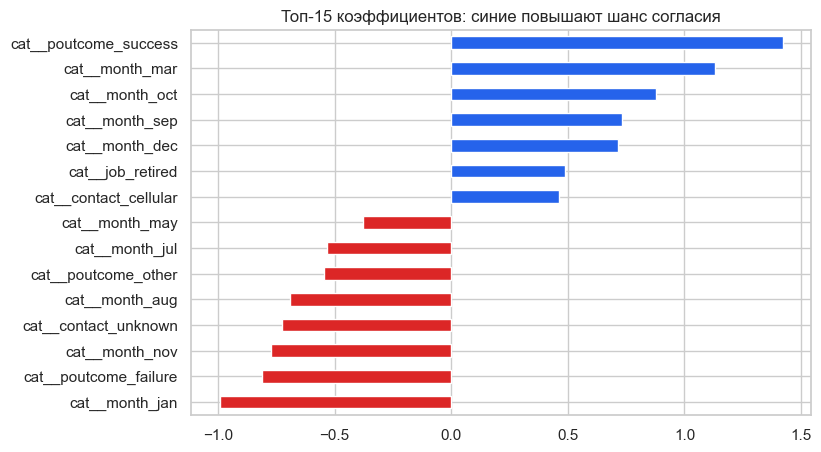

In [9]:
# Самые сильные коэффициенты логистической регрессии (признаки масштабированы, их можно сравнивать)
names = logreg_best[0][-1].get_feature_names_out()
coef = pd.Series(logreg_best[-1].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:15]).sort_values()
top.plot.barh(figsize=(8, 5), color=np.where(top > 0, "#2563eb", "#dc2626"))
plt.title("Топ-15 коэффициентов: синие повышают шанс согласия")
plt.show()

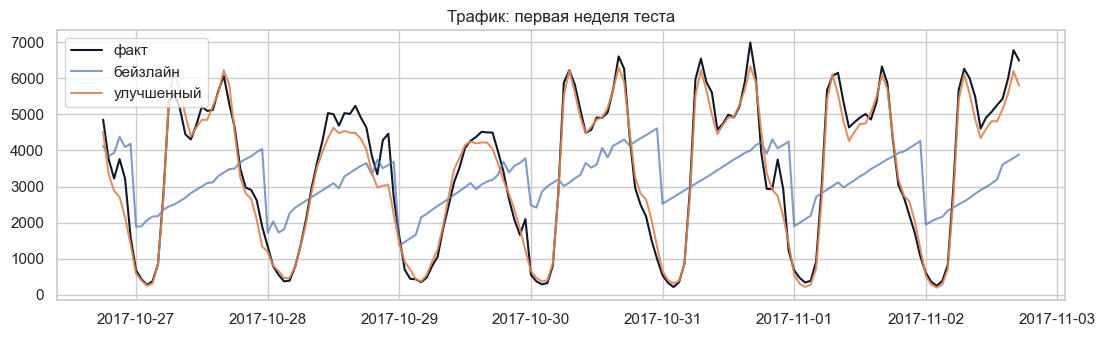

In [10]:
# Неделя из теста: бейзлайн против улучшенной модели
week = slice(0, 24 * 7)
plt.figure(figsize=(13, 3.5))
plt.plot(Xm_test.date_time.iloc[week], ym_test.iloc[week], label="факт", color="#0f172a")
plt.plot(Xm_test.date_time.iloc[week], linreg_base.predict(Xm_test.iloc[week]), label="бейзлайн", alpha=.7)
plt.plot(Xm_test.date_time.iloc[week], ridge_best.predict(Xm_test.iloc[week]), label="улучшенный", alpha=.9)
plt.legend()
plt.title("Трафик: первая неделя теста")
plt.show()

**Улучшенный бейзлайн против бейзлайна (тест).**

| | ROC-AUC | PR-AUC | F1 | MAE | R² |
|---|---|---|---|---|---|
| Бейзлайн | 0.771 | 0.410 | 0.280 | 1575.7 | 0.168 |
| Улучшенный | **0.773** | **0.413** | **0.447** | **291.6** | **0.948** |

- В классификации ранжирование почти не изменилось, зато F1 вырос с 0.28 до 0.45 за счёт весов классов и порога. Recall вырос с 18% до 46%.
- В регрессии улучшение огромное: ошибка уменьшилась в 5.4 раза. Хорошие признаки превратили линейную модель из бесполезной в одну из лучших.
- Самые сильные коэффициенты логистической регрессии. Повышают шанс согласия: успех прошлой кампании, звонки в марте, сентябре, октябре и декабре, пенсионеры, мобильная связь. Понижают: неудача прошлой кампании, неизвестный канал связи (`contact = unknown`), месяцы массовых обзвонов (май, июль, август, ноябрь, январь).

## 4. Собственная реализация

`mllabs/models/linear.py`:
- **`LinearRegressionScratch`** — МНК. Без регуляризации решается через `np.linalg.lstsq` (псевдообратная матрица устойчива к линейно зависимым one-hot столбцам), с L2 — через нормальные уравнения (XᵀX + αI)w = Xᵀy, свободный член не штрафуется.
- **`LogisticRegressionScratch`** — метод Ньютона (IRLS): на каждом шаге решается система H·Δw = ∇L, где H = XᵀWX + I/C, W = diag(p(1 − p)). Функционал как в sklearn: C·Σ logloss + ½‖w‖², `class_weight="balanced"` масштабирует потери объектов.

### 4.1. Те же условия, что у бейзлайна

In [11]:
# Своя логистическая регрессия на признаках бейзлайна (C = 1, без масштабирования)
own_clf = make_pipeline(bank_preprocessor(), LogisticRegressionScratch())
with Timer() as t:
    own_clf.fit(Xb_train, yb_train)
store.add("classification", "scratch", "LogisticRegressionScratch(C=1)",
          classification_metrics(yb_test, own_clf.predict_proba(Xb_test)[:, 1]), t.seconds)
print("Итераций Ньютона:", own_clf[-1].n_iter_)

# Своя линейная регрессия на признаках бейзлайна
own_reg = make_pipeline(metro_preprocessor(rich=False), LinearRegressionScratch())
with Timer() as t:
    own_reg.fit(Xm_train, ym_train)
store.add("regression", "scratch", "LinearRegressionScratch()",
          regression_metrics(ym_test, own_reg.predict(Xm_test)), t.seconds)
print("Макс. расхождение прогнозов с LinearRegression:",
      round(np.abs(own_reg.predict(Xm_test) - linreg_base.predict(Xm_test)).max(), 6))

display(store.table("classification").loc[["Бейзлайн sklearn", "Своя реализация"]])
display(store.table("regression").loc[["Бейзлайн sklearn", "Своя реализация"]])

Итераций Ньютона: 7
Макс. расхождение прогнозов с LinearRegression: 0.0


,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,LogisticRegression(),0.7709,0.4096,0.2799,0.6727,0.1767,0.5,5.0456
Своя реализация,LogisticRegressionScratch(C=1),0.7718,0.4110,0.2804,0.6643,0.1777,0.5,0.1775


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,LinearRegression(),1575.7271,1797.3501,0.1677,0.0552
Своя реализация,LinearRegressionScratch(),1575.7271,1797.3501,0.1677,0.0325


**Своя реализация против бейзлайна sklearn.**
- Линейная регрессия совпадает до последнего знака (максимальное расхождение прогнозов — 0).
- Логистическая регрессия: ROC-AUC 0.772 против 0.771. Метод Ньютона сходится за 7 итераций и находит точный минимум, а `lbfgs` в sklearn на немасштабированных данных останавливается чуть раньше. Заодно своя реализация обучается на порядок быстрее (доли секунды против нескольких секунд): метод Ньютона хорошо переносит плохую обусловленность, а квазиньютоновский `lbfgs` на немасштабированных признаках делает сотни итераций.

### 4.2. Своя реализация с техниками улучшенного бейзлайна

In [12]:
# Переносим признаки, масштабирование, C/веса классов и alpha
own_clf_best = make_pipeline(bank_preprocessor(rich=True, scale=True),
                             LogisticRegressionScratch(C=C, class_weight=cw))
thr_own = oof_threshold(own_clf_best, Xb_train, yb_train, bank_cv)
with Timer() as t:
    own_clf_best.fit(Xb_train, yb_train)
store.add("classification", "scratch_improved", f"LogisticRegressionScratch(C={C}, class_weight={cw}) + scale + features",
          classification_metrics(yb_test, own_clf_best.predict_proba(Xb_test)[:, 1], thr_own), t.seconds)

own_reg_best = make_pipeline(metro_preprocessor(REG_NUM, REG_CAT, scale=True), LinearRegressionScratch(alpha=alpha))
with Timer() as t:
    own_reg_best.fit(Xm_train, ym_train)
store.add("regression", "scratch_improved", f"LinearRegressionScratch(alpha={alpha}) + hour×daytype + clean weather",
          regression_metrics(ym_test, own_reg_best.predict(Xm_test)), t.seconds)

display(store.table("classification"))
display(store.table("regression"))

,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,LogisticRegression(),0.7709,0.4096,0.2799,0.6727,0.1767,0.50,5.0456
Улучшенный sklearn,"LogisticRegression(C=0.1, class_weight=balance...",0.7729,0.4130,0.4468,0.4340,0.4603,0.63,0.2546
Своя реализация,LogisticRegressionScratch(C=1),0.7718,0.4110,0.2804,0.6643,0.1777,0.50,0.1775
Своя реализация + улучшения,"LogisticRegressionScratch(C=0.1, class_weight=...",0.7728,0.4129,0.4472,0.4348,0.4603,0.63,0.1857


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,LinearRegression(),1575.7271,1797.3501,0.1677,0.0552
Улучшенный sklearn,Ridge(alpha=0.01) + hour×daytype + clean weather,291.5507,450.8679,0.9476,0.1151
Своя реализация,LinearRegressionScratch(),1575.7271,1797.3501,0.1677,0.0325
Своя реализация + улучшения,LinearRegressionScratch(alpha=0.01) + hour×day...,291.5507,450.8679,0.9476,0.1075


**Своя реализация с улучшениями против улучшенного sklearn.** Результаты совпадают: ROC-AUC 0.773, F1 0.447, тот же порог 0.63; MAE 291.6 и R² 0.948 — ровно как у `Ridge`. Улучшения из пункта 3 полностью переносятся в свою реализацию.

In [13]:
# Сохраняем метрики для итогового сравнения
print("Сохранено:", store.save().name)

Сохранено: lab2_linear.json


## 5. Выводы

1. Качество линейной модели определяется признаками. В регрессии переход от числа `hour` к взаимодействию «час × тип дня» уменьшил ошибку в 5 раз, а регуляризация при этом почти ничего не дала.
2. В классификации логистическая регрессия сразу даёт хорошее ранжирование (ROC-AUC 0.77). Улучшения в основном касаются решения при пороге: веса классов и подбор порога подняли F1 с 0.28 до 0.45.
3. Лучший результат: **ROC-AUC 0.773** и **MAE 292, R² 0.948**.
4. Собственные реализации совпадают со sklearn. Метод Ньютона для логистической регрессии к тому же быстрее `lbfgs` на немасштабированных данных.
5. Плюсы линейных моделей — интерпретируемость (коэффициенты видны на графике) и очень быстрое обучение, а цена — ручная работа над признаками.